# Milestone 2: Supervised learning
**Question:** do critic scores and game characteristics help predict a game's commercial success
(Low / Mid / High estimated owners)?



## 1. Setup

In [1]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay,
                             classification_report, make_scorer,
                             precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score, cross_validate, learning_curve,
                                     train_test_split, validation_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


DATA_PATH = "clean_steam_games.parquet"   # the finalized cleaned table from the team 
RANDOM_STATE = 42                         # reproducible
N_JOBS = -1                               # use all CPU cores
N_TREES = 300                             # random forest size (fixed, not tuned; see sensitivity in section 9)
PERM_REPEATS = 10                         # how many times each feature is shuffled in permutation importance

# Output folders for figures and tables (created if missing)
FIG_DIR, TAB_DIR = Path("figures"), Path("tables")
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

TIER_LABELS = ["Low (<20K owners)", "Mid (20K-100K owners)", "High (100K+ owners)"]
SHORT_LABELS = ["Low", "Mid", "High"]

# Steam genres that describe software or media rather than games.
# A row is dropped only if ALL of its genres are in this set (see load_data).
SOFTWARE_GENRES = {
    "Utilities", "Design & Illustration", "Animation & Modeling", "Education",
    "Video Production", "Game Development", "Audio Production", "Software Training",
    "Photo Editing", "Web Publishing", "Accounting", "Movie", "Documentary",
    "Episodic", "Short", "Tutorial", "360 Video",
}

np.random.seed(RANDOM_STATE)
# The saga solver for logistic regression can stop at its tolerance on a few folds; the warning is noise here.
warnings.filterwarnings("ignore", category=ConvergenceWarning)


def save_fig(fig, name):
    """Save a figure to the figures folder and show it in the notebook."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 2. Load data, filter non game rows, build the target
* Rows with no genre (dedicated servers, mod tools, comics) and software only titles are removed.
* Target: team tier definition based on the lower bound of `estimated_owners`
  (Low < 20K, Mid 20K to 100K, High 100K+). "0 - 0" rows are kept in Low by default.
* Metacritic: 0 means "no score", so it becomes a flag (`has_metacritic`) plus the score with missing values.

In [2]:
def leading_number(s):
    """Team helper: lower bound of an owners range, e.g. '20000 - 50000' -> 20000. Returns -1 if no number."""
    m = re.search(r'\d+', str(s).replace(',', ''))
    return int(m.group()) if m else -1


def owner_group(owners_range):
    """Team tier definition, returned as an ordered integer code (0 = Low, 1 = Mid, 2 = High)."""
    lo = leading_number(owners_range)
    if lo < 20_000:
        return 0
    elif lo < 100_000:
        return 1
    return 2


def load_data(path=DATA_PATH, zero_owners="merge_low"):
    """Load and filter the data.
    zero_owners: 'merge_low' keeps '0 - 0' rows in Low; 'drop' removes them (used in the sensitivity analysis).
    Returns the filtered dataframe and a log of row counts after each filtering step."""
    raw = pd.read_parquet(path)
    log = [("Loaded", len(raw))]

    # drop rows with an empty genre list (not games)
    df = raw[raw["genres"].apply(len) > 0]
    log.append(("Dropped rows with no genre (non game items)", len(df)))

    # Drop rows whose genres are ALL software genres (keeps any row with at least one game genre)
    df = df[~df["genres"].apply(lambda g: all(x in SOFTWARE_GENRES for x in g))]
    log.append(("Dropped software only titles", len(df)))

    if zero_owners == "drop":
        df = df[df["estimated_owners"] != "0 - 0"]
        log.append(('Dropped "0 - 0" owner rows', len(df)))

    df = df.reset_index(drop=True).copy()

    # Safety check: leading_number returns -1 for unreadable values, which owner_group would silently put in Low
    assert (df["estimated_owners"].map(leading_number) >= 0).all(), "unreadable estimated_owners value found"
    df["y"] = df["estimated_owners"].map(owner_group)

    # Consistency check with the team's shared table: its owner_group label must match our tiers exactly
    if "owner_group" in df.columns:
        team_y = df["owner_group"].map({label: code for code, label in enumerate(TIER_LABELS)})
        assert (team_y == df["y"]).all(), "tiers differ from the team's owner_group column"

    # Metacritic: 0 means "no score" -> flag + NaN (the NaN is median imputed inside the pipeline)
    df["has_metacritic"] = (df["metacritic_score"] > 0).astype(int)
    df["metacritic"] = df["metacritic_score"].where(df["metacritic_score"] > 0)
    return df, pd.DataFrame(log, columns=["step", "rows_remaining"])


df, filter_log = load_data()
filter_log.to_csv(TAB_DIR / "filter_log.csv", index=False)
print(filter_log.to_string(index=False))
print(df["y"].map(dict(enumerate(TIER_LABELS))).value_counts(normalize=True).round(3))

                                       step  rows_remaining
                                     Loaded          119036
Dropped rows with no genre (non game items)          110639
               Dropped software only titles          109481
y
Low (<20K owners)        0.795
Mid (20K-100K owners)    0.141
High (100K+ owners)      0.064
Name: proportion, dtype: float64


## 3. Features (hand picked) and how each one is encoded
* **Core set:** the features named in the proposal, plus `age` (time on the market) as a control,
  EXCEPT price. Price was dropped because the dataset records the price when the data was scraped,
  not the launch price, so it can reflect discounts or a switch to free to play after release.
  All main results use the core set.
* **Extended set:** core plus extra columns from feature engineering. Used only in the ablation (section 8).
* Feature selection works by listing the columns we want; anything not listed is never given to a model.

In [3]:
# Collect column groups by name prefix
GENRE_COLS = [c for c in df.columns if c.startswith("genre_")]
CAT_COLS = [c for c in df.columns if c.startswith("cat_") and c != "cat_trading_cards"]  # trading cards: leakage
LANG_COLS = [c for c in df.columns if c.startswith("lang_")]

# feature groups 
CORE_GROUPS = {
    "metacritic": ["has_metacritic", "metacritic"],
    "languages": ["total_langs"],
    "platforms": ["windows", "mac", "linux"],
    "genres": GENRE_COLS,
    "release_month": ["release_month"],
    "age": ["age"],
}
EXTENDED_GROUPS = {
    "categories": CAT_COLS,
    "publisher_history": ["pub_prior_games_max"],
    "language_flags": LANG_COLS + ["other_langs"],
}
# Flatten the groups into plain lists 
CORE = [c for cols in CORE_GROUPS.values() for c in cols]
EXTENDED = CORE + [c for cols in EXTENDED_GROUPS.values() for c in cols]

# Columns deliberately excluded (documented for the report).
# Nothing here removes them; they are excluded simply by not being in CORE or EXTENDED.
EXCLUDED = {
    "positive": "measured after release (reviews). Data leakage.",
    "negative": "measured after release (reviews). Data leakage.",
    "recommendations": "measured after release. Data leakage.",
    "peak_ccu": "measured after release (player counts). Data leakage.",
    "user_score": "measured after release. Data leakage.",
    "reviews": "measured after release",
    "score_rank": "measured after release",
    "cat_trading_cards": "Steam enables cards based on sales, partly encodes the outcome",
    "release_year": "redundant with age (r = -0.99)",
    "dev_prior_games_max": "correlated with pub_prior_games_max",
    "price": "recorded when the data was scraped, not at release (discounts, switches to free to play)",
    "owner_group": "the target itself (team's tier label), never a feature",
    "has_metacritic_score": "same as has_metacritic (team's version of the flag)",
}
# Safety check: stop with an error if an excluded column is ever added to a feature list
assert not set(EXCLUDED) & set(EXTENDED), "an excluded column slipped into the features"
print(pd.Series(EXCLUDED, name="reason").to_string())

# How each column is encoded (columns not listed here are 0/1 flags and pass through unchanged)
LOG_COLS = {"total_langs", "pub_prior_games_max", "other_langs"}  # heavily skewed -> log(1 + x), then scaled
IMPUTE_COLS = {"metacritic"}                                              # median imputed, then scaled
SCALE_COLS = {"age"}                                                      # standardized only
ONEHOT_COLS = {"release_month"}                                           # one hot (12 columns)


def make_preprocessor(cols):
    """Build a ColumnTransformer for any subset of feature columns (reused by the ablation).
    Each column goes to the step matching its encoding set above."""
    log_c = [c for c in cols if c in LOG_COLS]
    imp_c = [c for c in cols if c in IMPUTE_COLS]
    sc_c = [c for c in cols if c in SCALE_COLS]
    oh_c = [c for c in cols if c in ONEHOT_COLS]
    bin_c = [c for c in cols if c not in LOG_COLS | IMPUTE_COLS | SCALE_COLS | ONEHOT_COLS]
    parts = []
    if log_c:
        parts.append(("log", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                           StandardScaler()), log_c))
    if imp_c:
        parts.append(("meta", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), imp_c))
    if sc_c:
        parts.append(("scale", StandardScaler(), sc_c))
    if oh_c:
        parts.append(("onehot", OneHotEncoder(handle_unknown="ignore"), oh_c))
    if bin_c:
        parts.append(("binary", "passthrough", bin_c))
    # Columns not assigned to any step are dropped by default (a second safety layer)
    return ColumnTransformer(parts, verbose_feature_names_out=False)

positive                  measured after release (reviews). Data leakage.
negative                  measured after release (reviews). Data leakage.
recommendations                     measured after release. Data leakage.
peak_ccu                measured after release (player counts). Data l...
user_score                          measured after release. Data leakage.
reviews                                            measured after release
score_rank                                         measured after release
cat_trading_cards       Steam enables cards based on sales, partly enc...
release_year                               redundant with age (r = -0.99)
dev_prior_games_max                   correlated with pub_prior_games_max
price                   recorded when the data was scraped, not at rel...
owner_group             the target itself (team's tier label), never a...
has_metacritic_score    same as has_metacritic (team's version of the ...


## 4. Train / test split
Stratified on the tier so train and test have the same Low / Mid / High mix.
The test set is not touched until section 6.

In [4]:
# EXTENDED already contains CORE. appID, name and release_year are NOT features:
# they are kept only so the failure analysis can show which game was misclassified.
X, y = df[EXTENDED + ["appID", "name", "release_year"]], df["y"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (87584, 49)  Test: (21897, 49)


## 5. Models, hyperparameter grids and metrics
Three model families with different mechanisms (rubric requirement), plus a majority class baseline:
* Logistic regression: probabilistic, linear
* Random forest: tree based ensemble
* KNN: instance based

Logistic regression and random forest use `class_weight="balanced"` so the small Mid and High tiers count more.
Macro F1 is the main metric because the tiers are imbalanced (the baseline already gets 0.795 accuracy).

In [5]:
# each entry: (model, grid of hyperparameter values to search). "model__" points the setting at the
# pipeline step named "model" 
MODELS = {
    "Majority baseline": (DummyClassifier(strategy="most_frequent"), {}),
    "Logistic regression": (
        LogisticRegression(solver="saga", tol=1e-3, max_iter=2000, class_weight="balanced",
                           random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10],               # regularization strength (smaller = stronger)
         "model__l1_ratio": [0.0, 1.0]},               # 0 = L2 (default), 1 = L1 (sparse, interpretable)
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=N_TREES, class_weight="balanced", n_jobs=1,
                               random_state=RANDOM_STATE),
        {"model__max_depth": [10, 20, None],
         "model__min_samples_leaf": [1, 2, 5],          # widened: first grid's best (5) was at the edge
         "model__max_features": ["sqrt", 0.3, 0.5]},    # widened: first grid's best (0.3) was at the edge
    ),
    "KNN": (
        KNeighborsClassifier(n_jobs=1),
        {"model__n_neighbors": [1, 3, 5, 15],           # widened: first grid's best (5) was at the edge
         "model__weights": ["uniform", "distance"]},
    ),
}


def make_pipe(model, cols=CORE):
    """Preprocessing + model in one pipeline.
    clone() gives each pipeline its own copy of the model, so changing settings on one pipeline
    (for example with set_params) never changes the template stored in MODELS."""
    return Pipeline([("pre", make_preprocessor(cols)), ("model", clone(model))])


# Metrics reported in cross validation. Strings are scikit-learn's built-in scorers;
# make_scorer is used for precision and recall so zero_division can be set
# (the majority baseline never predicts Mid or High, which would otherwise give 0/0 warnings).
SCORING = {
    "accuracy": "accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": "f1_macro",
}
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)   # scores the models
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)   # picks hyperparameters

## 6. Nested cross validation: compare model families (core features)
Outer 5 folds score each family; inside every outer training fold, an inner 3 fold grid search picks
the hyperparameters. No model is ever scored on data used to choose its settings, so the mean ± std
below is an unbiased comparison (rubric requirement: mean and std across CV folds).

In [6]:
nested = {}
for name, (model, grid) in MODELS.items():
    t0 = time.time()
    est = make_pipe(model)
    if grid:
        # inner loop: tuning
        est = GridSearchCV(est, grid, cv=inner_cv, scoring="f1_macro", n_jobs=N_JOBS)
    # outer loop: scoring (passing a GridSearchCV into cross_validate is what makes it nested)
    res = cross_validate(est, X_train[CORE], y_train, cv=outer_cv, scoring=SCORING,
                         return_estimator=bool(grid), n_jobs=1 if grid else N_JOBS)
    # keep the hyperparameters chosen in each outer fold (shows how stable tuning is)
    res["best_params"] = [e.best_params_ for e in res.pop("estimator")] if grid else [{}] * 5
    nested[name] = res
    print(f"{name}: macro F1 {res['test_f1_macro'].mean():.3f}  ({(time.time() - t0) / 60:.1f} min)")

# Summary table: mean ± std of each metric across the 5 outer folds
rows = []
for name, res in nested.items():
    row = {"Model": name}
    for m in SCORING:
        row[m] = f"{res[f'test_{m}'].mean():.3f} ± {res[f'test_{m}'].std():.3f}"
    row["fit_time_s"] = f"{res['fit_time'].mean():.1f}"
    row["score_time_s"] = f"{res['score_time'].mean():.1f}"
    rows.append(row)
summary = pd.DataFrame(rows)
summary.to_csv(TAB_DIR / "model_comparison_nested_cv.csv", index=False)
print(summary.to_string(index=False))

# Best hyperparameters chosen in each outer fold
params_per_fold = pd.DataFrame(
    [{"Model": n, "outer_fold": i + 1, **p} for n, r in nested.items() for i, p in enumerate(r["best_params"])])
params_per_fold.to_csv(TAB_DIR / "best_params_per_outer_fold.csv", index=False)
print(params_per_fold.to_string(index=False))

Majority baseline: macro F1 0.295  (0.0 min)
Logistic regression: macro F1 0.455  (3.6 min)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Random forest: macro F1 0.509  (61.9 min)
KNN: macro F1 0.457  (4.0 min)
              Model      accuracy precision_macro  recall_macro      f1_macro fit_time_s score_time_s
  Majority baseline 0.795 ± 0.000   0.265 ± 0.000 0.333 ± 0.000 0.295 ± 0.000        0.1          0.0
Logistic regression 0.613 ± 0.003   0.446 ± 0.002 0.541 ± 0.004 0.455 ± 0.002       43.5          0.0
      Random forest 0.690 ± 0.005   0.495 ± 0.004 0.548 ± 0.007 0.509 ± 0.005      741.8          1.0
                KNN 0.763 ± 0.001   0.493 ± 0.004 0.440 ± 0.004 0.457 ± 0.004       46.2          2.1
              Model  outer_fold  model__C  model__l1_ratio  model__max_depth model__max_features  model__min_samples_leaf  model__n_neighbors model__weights
  Majority baseline           1       NaN              NaN               NaN                 NaN                      NaN                 NaN            NaN
  Majority baseline           2       NaN              NaN               NaN                 NaN       

## 6 (continued). Final model: tune the best family on all training data, evaluate once on the test set

Best model family: Random forest
Best params: {'model__max_depth': 20, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}  CV macro F1: 0.509
                       precision    recall  f1-score   support

    Low (<20K owners)      0.896     0.741     0.811     17403
Mid (20K-100K owners)      0.249     0.449     0.320      3096
  High (100K+ owners)      0.346     0.472     0.400      1398

             accuracy                          0.683     21897
            macro avg      0.497     0.554     0.510     21897
         weighted avg      0.769     0.683     0.715     21897



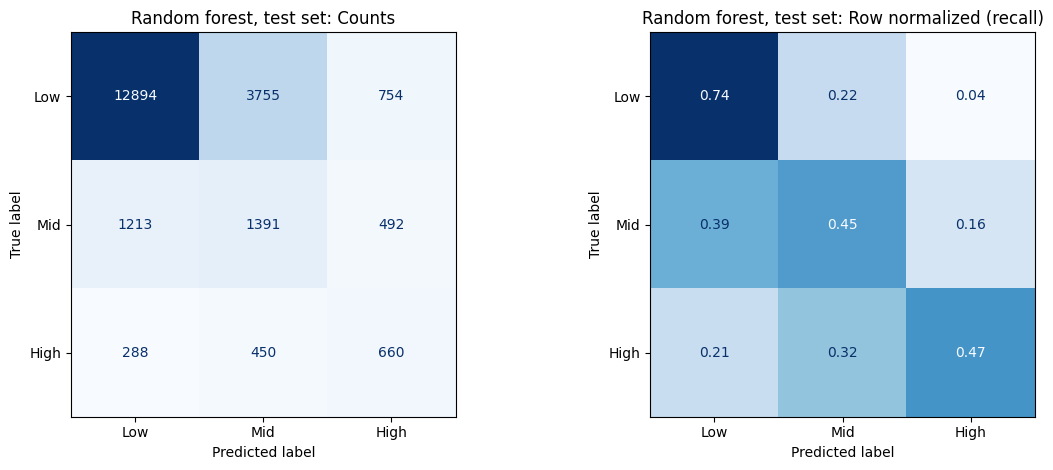

In [7]:
# Best family = highest mean nested CV macro F1 (the baseline is excluded)
BEST_NAME = max((n for n in nested if n != "Majority baseline"),
                key=lambda n: nested[n]["test_f1_macro"].mean())
print("Best model family:", BEST_NAME)

final_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def tune(name, cols=CORE):
    """Grid search one model family on the full training set with 5 fold CV.
    With refit=True (the default), the best setting is retrained on all training data
    and stored in search.best_estimator_."""
    model, grid = MODELS[name]
    search = GridSearchCV(make_pipe(model, cols), grid, cv=final_cv, scoring="f1_macro", n_jobs=N_JOBS)
    search.fit(X_train[cols], y_train)
    return search


best_search = tune(BEST_NAME)
best_model = best_search.best_estimator_      # the final pipeline (preprocessing + tuned model)
BEST_PARAMS = best_search.best_params_        # reused by the ablation and sensitivity analyses
# Note: best_score_ is used only to pick settings; the model comparison above uses nested CV scores.
print("Best params:", BEST_PARAMS, " CV macro F1:", round(best_search.best_score_, 3))
pd.DataFrame(best_search.cv_results_).to_csv(TAB_DIR / "final_grid_search_results.csv", index=False)

# The one and only evaluation on the test set
y_pred = best_model.predict(X_test[CORE])
report = classification_report(y_test, y_pred, target_names=TIER_LABELS, digits=3, output_dict=True)
pd.DataFrame(report).T.round(3).to_csv(TAB_DIR / "test_classification_report.csv")
print(classification_report(y_test, y_pred, target_names=TIER_LABELS, digits=3))

# Confusion matrix: rows = true tier, columns = predicted tier.
# Left: raw counts. Right: each row divided by its total, so the diagonal is each tier's recall.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, norm, title in [(axes[0], None, "Counts"), (axes[1], "true", "Row normalized (recall)")]:
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=SHORT_LABELS, normalize=norm,
                                            values_format=".2f" if norm else "d", cmap="Blues",
                                            ax=ax, colorbar=False)
    ax.set_title(f"{BEST_NAME}, test set: {title}")
save_fig(fig, "confusion_matrix_test")

## 7. Feature importance: permutation importance (rubric: feature importance)
Shuffle one feature at a time on the test set and measure the drop in macro F1 (no retraining).
Chosen over random forest's built-in importance because it is measured on unseen data and is not
biased toward continuous features. Shuffling happens on the raw columns, so release month counts as one feature.

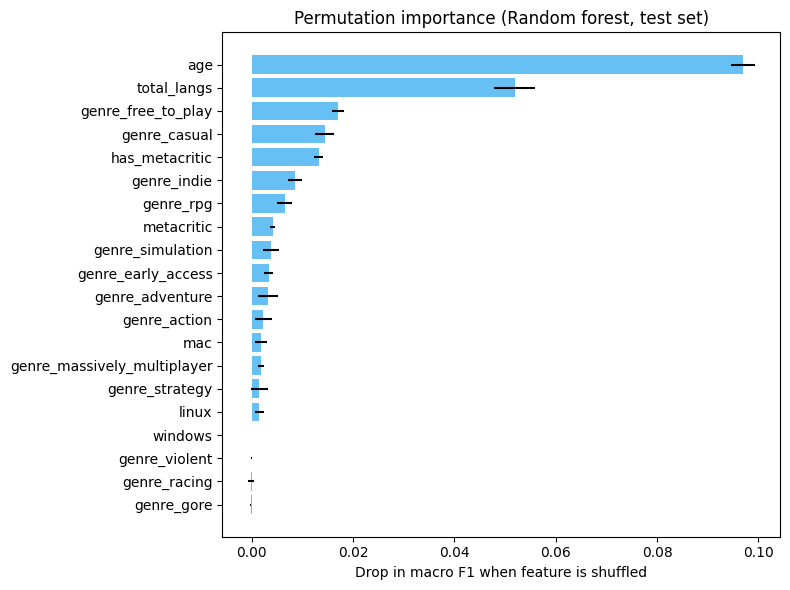

In [8]:
perm = permutation_importance(best_model, X_test[CORE], y_test, scoring="f1_macro",
                              n_repeats=PERM_REPEATS, random_state=RANDOM_STATE, n_jobs=N_JOBS)
imp = (pd.DataFrame({"feature": CORE, "mean_drop_f1": perm.importances_mean, "std": perm.importances_std})
         .sort_values("mean_drop_f1", ascending=False))
imp.round(4).to_csv(TAB_DIR / "permutation_importance.csv", index=False)

# Top 20 features; reversed so the most important ends up at the top of the chart
top = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["mean_drop_f1"], xerr=top["std"], color="#66c0f4")  # steam colors: #2a475e, #1b2838, #66c0f4, #171a21, #c7d5e0
ax.set_xlabel("Drop in macro F1 when feature is shuffled")
ax.set_title(f"Permutation importance ({BEST_NAME}, test set)")
save_fig(fig, "permutation_importance")

## 8. Ablation 
Retrain the best model with one core feature group removed (or one extended group added) and compare
5 fold CV macro F1 against all core features. Hyperparameters stay fixed at the tuned values.

                feature_set  f1_macro_mean  f1_macro_std  change_vs_core
          All core features         0.5089        0.0051          0.0000
      Core minus metacritic         0.4955        0.0061         -0.0134
       Core minus languages         0.4639        0.0050         -0.0451
       Core minus platforms         0.5018        0.0031         -0.0071
          Core minus genres         0.4280        0.0023         -0.0809
   Core minus release_month         0.5016        0.0053         -0.0073
             Core minus age         0.4263        0.0027         -0.0826
       Core plus categories         0.5355        0.0084          0.0266
Core plus publisher_history         0.5260        0.0059          0.0170
   Core plus language_flags         0.5199        0.0059          0.0109
      Extended (all groups)         0.5508        0.0044          0.0419


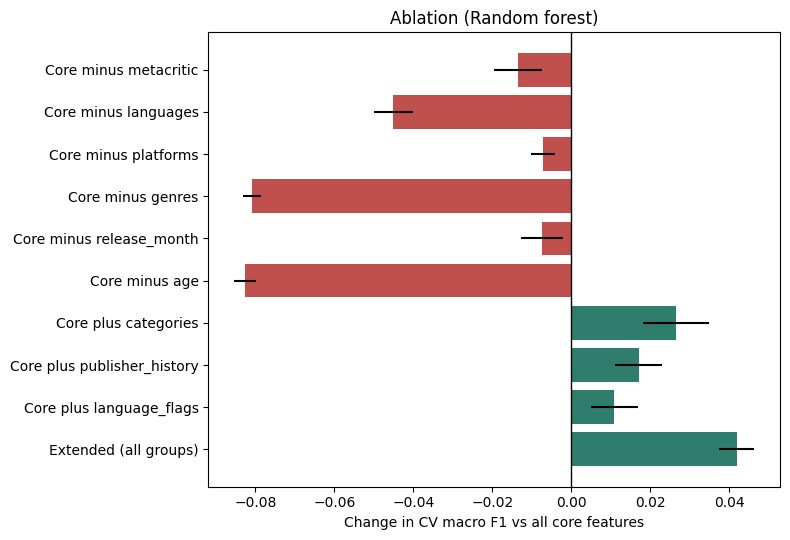

In [9]:
best_estimator_template = MODELS[BEST_NAME][0]   # untrained best model family, used as a template


def cv_f1(cols, data_X=None, data_y=None, **param_overrides):
    """5 fold CV macro F1 (mean, std) of the best model on the given columns.
    data_X / data_y default to the training set; param_overrides changes individual settings,
    e.g. cv_f1(CORE, model__class_weight=None)."""
    data_X = X_train if data_X is None else data_X
    data_y = y_train if data_y is None else data_y
    # tuned settings first, then any overrides (later keys win when the two dictionaries are merged)
    pipe = make_pipe(best_estimator_template, cols).set_params(**{**BEST_PARAMS, **param_overrides})
    s = cross_val_score(pipe, data_X[cols], data_y, cv=final_cv, scoring="f1_macro", n_jobs=N_JOBS)
    return s.mean(), s.std()


abl = [("All core features", *cv_f1(CORE))]                     # reference run
for g, cols in CORE_GROUPS.items():                              # remove one core group at a time
    abl.append((f"Core minus {g}", *cv_f1([c for c in CORE if c not in cols])))
for g, cols in EXTENDED_GROUPS.items():                          # add one extended group at a time
    abl.append((f"Core plus {g}", *cv_f1(CORE + cols)))
abl.append(("Extended (all groups)", *cv_f1(EXTENDED)))

ablation = pd.DataFrame(abl, columns=["feature_set", "f1_macro_mean", "f1_macro_std"])
ablation["change_vs_core"] = ablation["f1_macro_mean"] - ablation.loc[0, "f1_macro_mean"]
ablation.round(4).to_csv(TAB_DIR / "ablation.csv", index=False)
print(ablation.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5.5))
a = ablation.iloc[1:].iloc[::-1]
ax.barh(a["feature_set"], a["change_vs_core"], xerr=a["f1_macro_std"],
        color=np.where(a["change_vs_core"] < 0, "#c0504d", "#2f7d6d"))
ax.axvline(0, c="k", lw=1)
ax.set_xlabel("Change in CV macro F1 vs all core features")
ax.set_title(f"Ablation ({BEST_NAME})")
save_fig(fig, "ablation")

## 9. Sensitivity analysis 
### 9a. Hyperparameters
Starts from the tuned settings and changes ONE hyperparameter at a time (validation curves).
This does not choose settings (section 6 did); it shows how sensitive the final model is to them.
The number of trees was fixed at 300 rather than tuned, since more trees plateau instead of overfitting.

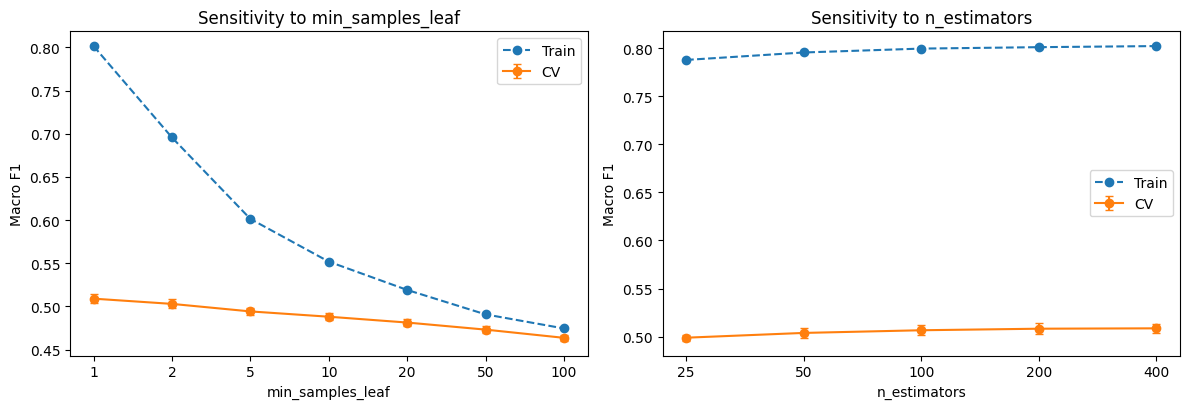

In [10]:
SENSITIVITY_PARAMS = {
    "Random forest": [("model__min_samples_leaf", [1, 2, 5, 10, 20, 50, 100]),
                      ("model__n_estimators", [25, 50, 100, 200, 400])],
    "Logistic regression": [("model__C", [0.001, 0.01, 0.1, 1, 10, 100])],
    "KNN": [("model__n_neighbors", [1, 5, 15, 35, 75, 150])],
}
sens_params = SENSITIVITY_PARAMS[BEST_NAME]
fig, axes = plt.subplots(1, len(sens_params), figsize=(6 * len(sens_params), 4.2), squeeze=False)
for ax, (param, values) in zip(axes[0], sens_params):
    pipe = make_pipe(best_estimator_template).set_params(**BEST_PARAMS)
    # tr = scores on the training folds, va = scores on the held out fold (the one that matters)
    tr, va = validation_curve(pipe, X_train[CORE], y_train, param_name=param, param_range=values,
                              cv=final_cv, scoring="f1_macro", n_jobs=N_JOBS)
    pd.DataFrame({"value": values, "train_mean": tr.mean(1), "cv_mean": va.mean(1), "cv_std": va.std(1)}) \
      .round(4).to_csv(TAB_DIR / f"sensitivity_{param.split('__')[1]}.csv", index=False)
    xs = [str(v) for v in values]
    ax.plot(xs, tr.mean(1), "o--", label="Train")
    ax.errorbar(xs, va.mean(1), yerr=va.std(1), fmt="o-", capsize=3, label="CV")
    ax.set_xlabel(param.split("__")[1]); ax.set_ylabel("Macro F1"); ax.legend()
    ax.set_title(f"Sensitivity to {param.split('__')[1]}")
save_fig(fig, "sensitivity_hyperparameters")

### 9b. Other solution choices
* Class weights on vs off
* Keeping "0 - 0" owner rows in Low vs dropping them (uses its own stratified split of the reduced data)

In [11]:
sens_rows = [("Best model (as tuned)", *cv_f1(CORE))]
if "class_weight" in best_estimator_template.get_params():
    sens_rows.append(("No class weights", *cv_f1(CORE, model__class_weight=None)))

df_drop, _ = load_data(zero_owners="drop")
Xd_train, _, yd_train, _ = train_test_split(df_drop[EXTENDED], df_drop["y"], test_size=0.2,
                                            stratify=df_drop["y"], random_state=RANDOM_STATE)
sens_rows.append(('"0 - 0" owner rows dropped', *cv_f1(CORE, Xd_train, yd_train)))

sensitivity = pd.DataFrame(sens_rows, columns=["variant", "f1_macro_mean", "f1_macro_std"])
sensitivity.round(4).to_csv(TAB_DIR / "sensitivity_variants.csv", index=False)
print(sensitivity.round(4).to_string(index=False))

                   variant  f1_macro_mean  f1_macro_std
     Best model (as tuned)         0.5089        0.0051
          No class weights         0.4586        0.0087
"0 - 0" owner rows dropped         0.5116        0.0056


## 10. Tradeoffs
* Learning curve: training data size vs macro F1
* High tier precision vs recall (one vs rest), from predicted probabilities
* Speed vs performance across model families (from nested CV)

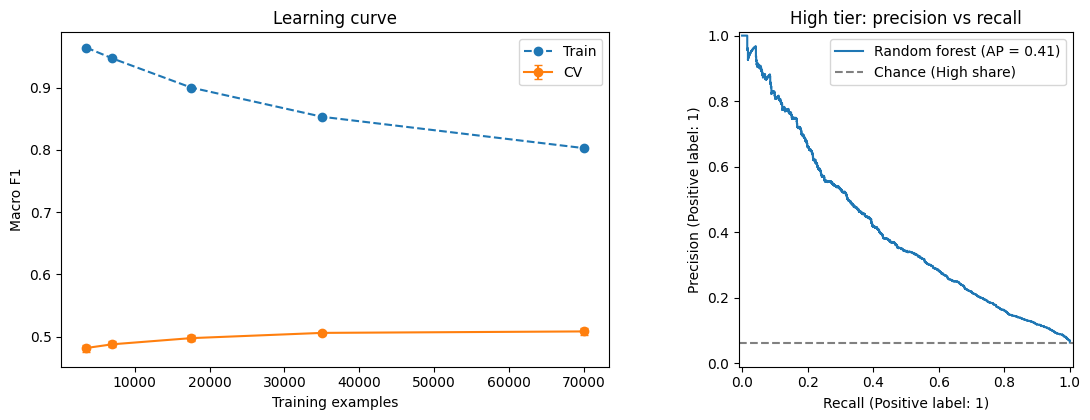

                     f1_macro  fit_time_s  score_time_s
Majority baseline       0.295       0.088         0.034
Logistic regression     0.455      43.503         0.027
Random forest           0.509     741.750         0.984
KNN                     0.457      46.225         2.072


In [12]:
# (a) Learning curve
lc_sizes, lc_tr, lc_va = learning_curve(best_model, X_train[CORE], y_train,
                                        train_sizes=[0.05, 0.1, 0.25, 0.5, 1.0],
                                        cv=final_cv, scoring="f1_macro", n_jobs=N_JOBS, shuffle=True,
                                        random_state=RANDOM_STATE)
pd.DataFrame({"n_train": lc_sizes, "train_mean": lc_tr.mean(1), "cv_mean": lc_va.mean(1), "cv_std": lc_va.std(1)}) \
  .round(4).to_csv(TAB_DIR / "learning_curve.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(lc_sizes, lc_tr.mean(1), "o--", label="Train")
axes[0].errorbar(lc_sizes, lc_va.mean(1), yerr=lc_va.std(1), fmt="o-", capsize=3, label="CV")
axes[0].set_xlabel("Training examples"); axes[0].set_ylabel("Macro F1")
axes[0].set_title("Learning curve"); axes[0].legend()

# (b) Precision vs recall for the High tier: "High or not", ranked by the predicted probability of High.
# Moving right = lower threshold = more games flagged as High. Dashed line = chance (share of High games).
proba = best_model.predict_proba(X_test[CORE])   # also reused by the failure analysis (section 11)
PrecisionRecallDisplay.from_predictions((y_test == 2).astype(int), proba[:, 2], ax=axes[1], name=BEST_NAME)
axes[1].axhline((y_test == 2).mean(), ls="--", c="grey", label="Chance (High share)")
axes[1].set_title("High tier: precision vs recall"); axes[1].legend()
save_fig(fig, "tradeoffs")

# (c) Speed vs performance across families (mean fit / score time per outer fold of nested CV)
speed = pd.DataFrame({n: {"f1_macro": r["test_f1_macro"].mean(),
                          "fit_time_s": r["fit_time"].mean(), "score_time_s": r["score_time"].mean()}
                      for n, r in nested.items()}).T.round(3)
speed.to_csv(TAB_DIR / "speed_vs_performance.csv")
print(speed)

## 11. Failure analysis 
Collects the test set mistakes so they can be read and grouped into failure categories by hand.
* `test_errors_all.csv`: every mistake, most confident first
* `failure_examples.csv`: the 8 most confident mistakes of each error type
* `failure_profiles.csv`: average features of correct vs misclassified games within each true tier

In [13]:
# One row per test game: identifiers, features, true and predicted tier, and predicted probabilities
fa = X_test[["appID", "name", "release_year"] + CORE].copy()
fa["true"] = y_test.map(dict(enumerate(SHORT_LABELS))).values                       # 0/1/2 -> Low/Mid/High
fa["pred"] = pd.Series(y_pred, index=X_test.index).map(dict(enumerate(SHORT_LABELS)))
for i, lab in enumerate(SHORT_LABELS):
    fa[f"p_{lab}"] = proba[:, i].round(3)
fa["confidence_in_pred"] = proba.max(axis=1).round(3)   # probability of the predicted tier

# Keep only the mistakes; the most confident (most surprising) first
errors = fa[fa["true"] != fa["pred"]].sort_values("confidence_in_pred", ascending=False)
errors.to_csv(TAB_DIR / "test_errors_all.csv", index=False)

print("Error types (true -> predicted):")
print(errors.groupby(["true", "pred"]).size().rename("n").reset_index().to_string(index=False))

# 8 most confident mistakes of EACH error type, so every kind of mistake is represented
show_cols = ["name", "release_year", "true", "pred", "confidence_in_pred", "has_metacritic",
             "metacritic", "total_langs", "age", "genre_free_to_play", "genre_indie", "genre_early_access"]
examples = (errors.groupby(["true", "pred"], group_keys=False).head(8)[show_cols])
examples.to_csv(TAB_DIR / "failure_examples.csv", index=False)
print(examples.to_string(index=False))

# Compare errors with correct predictions inside the same true tier (what makes them different?)
compare_cols = ["has_metacritic", "total_langs", "age", "genre_free_to_play", "genre_early_access",
                "genre_indie", "genre_massively_multiplayer", "mac", "linux"]
fa["outcome"] = np.where(fa["true"] == fa["pred"], "correct", "pred " + fa["pred"])
profile = fa.groupby(["true", "outcome"])[compare_cols].mean().round(3)
profile["n"] = fa.groupby(["true", "outcome"]).size()
profile.to_csv(TAB_DIR / "failure_profiles.csv")
print(profile.to_string())

Error types (true -> predicted):
true pred    n
High  Low  288
High  Mid  450
 Low High  754
 Low  Mid 3755
 Mid High  492
 Mid  Low 1213
                                              name  release_year true pred  confidence_in_pred  has_metacritic  metacritic  total_langs       age  genre_free_to_play  genre_indie  genre_early_access
                                        Vaudeville          2025  Mid  Low               0.968               0         NaN            1  0.826831                   0            1                   0
                Reentry - A Space Flight Simulator          2025 High  Low               0.951               0         NaN            1  0.884326                   0            1                   0
                                          Pile Up!          2025 High  Low               0.945               0         NaN           10  1.177276                   0            1                   0
                          3D PUZZLE - Modern House          2022  

## 12. Subgroup analysis: games with a Metacritic score
**Question:** among games that critics reviewed (a more visible, comparable group),
does a higher Metacritic score go with more owners?



Scored games: 2213 train, 596 test
      train_n  test_n  train_pct  test_pct
Low       433     102       19.6      17.1
Mid       581     164       26.3      27.5
High     1199     330       54.2      55.4
Majority baseline: macro F1 0.234  (0.0 min)
Logistic regression: macro F1 0.520  (0.1 min)
Random forest: macro F1 0.544  (1.3 min)
KNN: macro F1 0.487  (0.0 min)
              Model      accuracy precision_macro  recall_macro      f1_macro
  Majority baseline 0.542 ± 0.001   0.181 ± 0.000 0.333 ± 0.000 0.234 ± 0.000
Logistic regression 0.567 ± 0.015   0.519 ± 0.012 0.534 ± 0.012 0.520 ± 0.011
      Random forest 0.591 ± 0.019   0.544 ± 0.017 0.548 ± 0.018 0.544 ± 0.018
                KNN 0.584 ± 0.016   0.514 ± 0.018 0.481 ± 0.017 0.487 ± 0.017
Best family on scored games: Random forest
Best params: {'model__max_depth': 10, 'model__max_features': 0.3, 'model__min_samples_leaf': 5}  CV macro F1: 0.551
                        variant  f1_macro_mean  f1_macro_std
          With meta

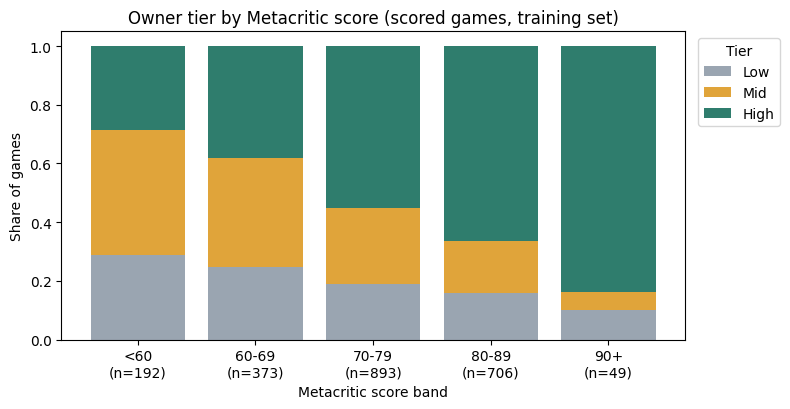

                       precision    recall  f1-score   support

    Low (<20K owners)      0.336     0.461     0.388       102
Mid (20K-100K owners)      0.365     0.402     0.383       164
  High (100K+ owners)      0.745     0.621     0.678       330

             accuracy                          0.534       596
            macro avg      0.482     0.495     0.483       596
         weighted avg      0.571     0.534     0.547       596



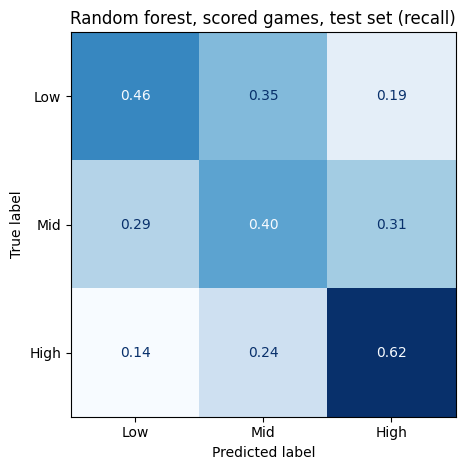

In [14]:
SUB_CORE = [c for c in CORE if c != "has_metacritic"]
tr_mask = X_train["has_metacritic"] == 1
te_mask = X_test["has_metacritic"] == 1
Xs_tr, ys_tr = X_train.loc[tr_mask, SUB_CORE], y_train[tr_mask]
Xs_te, ys_te = X_test.loc[te_mask, SUB_CORE], y_test[te_mask]

# Sample size and tier balance (train vs test)
sub_sizes = pd.DataFrame({"train_n": ys_tr.value_counts().sort_index(),
                          "test_n": ys_te.value_counts().sort_index()})
sub_sizes.index = SHORT_LABELS
sub_sizes["train_pct"] = (100 * sub_sizes["train_n"] / sub_sizes["train_n"].sum()).round(1)
sub_sizes["test_pct"] = (100 * sub_sizes["test_n"] / sub_sizes["test_n"].sum()).round(1)
sub_sizes.to_csv(TAB_DIR / "subgroup_scored_sizes.csv")
print(f"Scored games: {len(Xs_tr)} train, {len(Xs_te)} test")
print(sub_sizes)

# 12b. Model family comparison with nested CV (same design as section 6) 
sub_nested = {}
for name, (model, grid) in MODELS.items():
    t0 = time.time()
    est = make_pipe(model, SUB_CORE)
    if grid:
        est = GridSearchCV(est, grid, cv=inner_cv, scoring="f1_macro", n_jobs=N_JOBS)
    res = cross_validate(est, Xs_tr, ys_tr, cv=outer_cv, scoring=SCORING,
                         n_jobs=1 if grid else N_JOBS)
    sub_nested[name] = res
    print(f"{name}: macro F1 {res['test_f1_macro'].mean():.3f}  ({(time.time() - t0) / 60:.1f} min)")

sub_summary = pd.DataFrame([
    {"Model": n, **{m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in SCORING}}
    for n, r in sub_nested.items()])
sub_summary.to_csv(TAB_DIR / "subgroup_scored_model_comparison.csv", index=False)
print(sub_summary.to_string(index=False))

SUB_BEST = max((n for n in sub_nested if n != "Majority baseline"),
               key=lambda n: sub_nested[n]["test_f1_macro"].mean())
print("Best family on scored games:", SUB_BEST)

# 12c. Tune the best family on all scored training games
sub_model, sub_grid = MODELS[SUB_BEST]
sub_search = GridSearchCV(make_pipe(sub_model, SUB_CORE), sub_grid, cv=final_cv,
                          scoring="f1_macro", n_jobs=N_JOBS).fit(Xs_tr, ys_tr)
SUB_PARAMS = sub_search.best_params_
print("Best params:", SUB_PARAMS, " CV macro F1:", round(sub_search.best_score_, 3))

# 12d. Does the score itself help? With vs without `metacritic` (paired, repeated CV) 
rep_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)


def sub_scores(cols):
    """Macro F1 on each of the 25 repeated CV splits for the tuned subgroup model on the given columns."""
    pipe = make_pipe(sub_model, cols).set_params(**SUB_PARAMS)
    return cross_val_score(pipe, Xs_tr[cols], ys_tr, cv=rep_cv, scoring="f1_macro", n_jobs=N_JOBS)


with_score = sub_scores(SUB_CORE)
without_score = sub_scores([c for c in SUB_CORE if c != "metacritic"])
diff = with_score - without_score   # same 25 splits for both, so the comparison is paired

score_test = pd.DataFrame({
    "variant": ["With metacritic score", "Without metacritic score", "Difference (with minus without)"],
    "f1_macro_mean": [with_score.mean(), without_score.mean(), diff.mean()],
    "f1_macro_std": [with_score.std(), without_score.std(), diff.std()],
})
score_test.round(4).to_csv(TAB_DIR / "subgroup_scored_metacritic_ablation.csv", index=False)
print(score_test.round(4).to_string(index=False))
print(f"Splits where the score helped: {(diff > 0).sum()} of {len(diff)}")


bands = pd.cut(Xs_tr["metacritic"], bins=[0, 59, 69, 79, 89, 100],
               labels=["<60", "60-69", "70-79", "80-89", "90+"])
tier_by_band = pd.crosstab(bands, ys_tr.map(dict(enumerate(SHORT_LABELS))), normalize="index")[SHORT_LABELS]
tier_by_band["n"] = bands.value_counts().reindex(tier_by_band.index)
tier_by_band.round(3).to_csv(TAB_DIR / "subgroup_scored_tier_by_score_band.csv")
print(tier_by_band.round(3))

fig, ax = plt.subplots(figsize=(8, 4.2))
tier_by_band[SHORT_LABELS].plot(kind="bar", stacked=True, ax=ax, width=0.8,
                                color=["#9aa5b1", "#e0a43a", "#2f7d6d"])
ax.set_xlabel("Metacritic score band"); ax.set_ylabel("Share of games")
ax.set_title("Owner tier by Metacritic score (scored games, training set)")
ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(tier_by_band.index, tier_by_band["n"])], rotation=0)
ax.legend(title="Tier", bbox_to_anchor=(1.01, 1), loc="upper left")
save_fig(fig, "subgroup_scored_tier_by_score_band")

#  One time evaluation on scored games in the held out test set
ys_pred = sub_search.best_estimator_.predict(Xs_te)
print(classification_report(ys_te, ys_pred, target_names=TIER_LABELS, digits=3))
pd.DataFrame(classification_report(ys_te, ys_pred, target_names=TIER_LABELS, digits=3, output_dict=True)) \
  .T.round(3).to_csv(TAB_DIR / "subgroup_scored_test_report.csv")

fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay.from_predictions(ys_te, ys_pred, display_labels=SHORT_LABELS, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"{SUB_BEST}, scored games, test set (recall)")
save_fig(fig, "subgroup_scored_confusion_matrix")